# Does party control matter? Explorer notebook

Every chart and table behind the write-up, built from the files in `data/` and `results/`.
Run top to bottom (**Kernel → Restart & Run All**). Nothing here re-estimates the models;
to regenerate `results/`, run the scripts in `src/` (see README).

**Colour key used throughout:** blue = Democratic, red = Republican, grey = not significant / neutral.

Sections
1. Who governed, 1900–2025
2. Every outcome over time, shaded by the president's party
3. Term-level test: Democratic vs Republican terms
4. Equivalence: which nulls are actually *proven*
5. All 210 primary tests at a glance (naive vs rotation p-values)
6. Why the Congress "effects" are artifacts
7. The alternative hypothesis: inherited conditions
8. Machine-learning check
9. Reverse causality: does the economy pick the party?
10. Full output tables
11. Plot any outcome yourself

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, RES = ROOT / "data", ROOT / "results"
import sys; sys.path.insert(0, str(ROOT / "src"))
from analysis import OUTCOMES   # labels, units, smallest-effect thresholds

# Palette (validated: blue/red pass colour-vision-deficiency separation)
D, R = "#2a78d6", "#e34948"
GREY, INK, INK2, GRID, SURF = "#a8a7a0", "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "lines.linewidth": 1.6, "figure.dpi": 110,
})
pd.set_option("display.max_rows", 500, "display.max_columns", 50, "display.width", 200)

panel = pd.read_csv(DATA / "panel.csv", index_col=0)
term_tests = pd.read_csv(RES / "term_level_tests.csv")
term_vals = pd.read_csv(RES / "term_level_values.csv")
annual = pd.read_csv(RES / "annual_models.csv")
rot = pd.read_csv(RES / "robust_trend_rotation.csv")
subp = pd.read_csv(RES / "robust_subperiods.csv")
ml = pd.read_csv(RES / "ml_predictive_test.csv")
alt = pd.read_csv(RES / "alternative_inherited_conditions.csv")
stress = pd.read_csv(RES / "alternative_post_wwii_stress.csv")
elec = pd.read_csv(RES / "elections_reverse_causality.csv")
label = {k: v[1] for k, v in OUTCOMES.items()}
units = {k: v[2] for k, v in OUTCOMES.items()}

def shade_presidents(ax, y0=1900, y1=2025, alpha=0.10):
    # Light background band per year: blue = Democratic president, red = Republican
    for yr, party in panel.loc[y0:y1, "pres_party"].items():
        ax.axvspan(yr - 0.5, yr + 0.5, color=D if party == "D" else R, alpha=alpha, lw=0)

def label_points(ax, xs, ys, texts, frac=0.045, **kw):
    # Greedy labelling: skip a label if it would land too close to one already placed
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim(); placed = []
    for x, y, t in sorted(zip(xs, ys, texts), key=lambda r: -abs(r[1])):
        nx, ny = (x - x0) / (x1 - x0), (y - y0) / (y1 - y0)
        if all(abs(nx - px) > 2.2 * frac or abs(ny - py) > frac for px, py in placed):
            ax.annotate(t, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=INK2, **kw)
            placed.append((nx, ny))

display(Markdown("**Headline (results/summary.json)**"))
print(json.dumps(json.load(open(RES / "summary.json")), indent=2))

**Headline (results/summary.json)**

{
  "n_primary_tests": 210,
  "primary_raw_p_lt_05": 33,
  "primary_q_lt_05": 7,
  "primary_q_lt_10": 12,
  "block_perm_q_lt_05": 0,
  "term_q_lt_05": 0,
  "term_equivalent_at_05": 2,
  "reverse_causality": {
    "logit_coef_gdp": 0.09682875203017018,
    "logit_p": 0.20600087653326238,
    "n": 32,
    "pointbiserial_r": 0.2364997208996626,
    "pointbiserial_p": 0.19250792705798805,
    "kept_mean_growth": 2.6050664657317117,
    "lost_mean_growth": 0.06941500132115717
  }
}


## 1. Who governed, 1900–2025
Each row is one branch; each cell is one year. The bottom strip marks years when one party held all three.

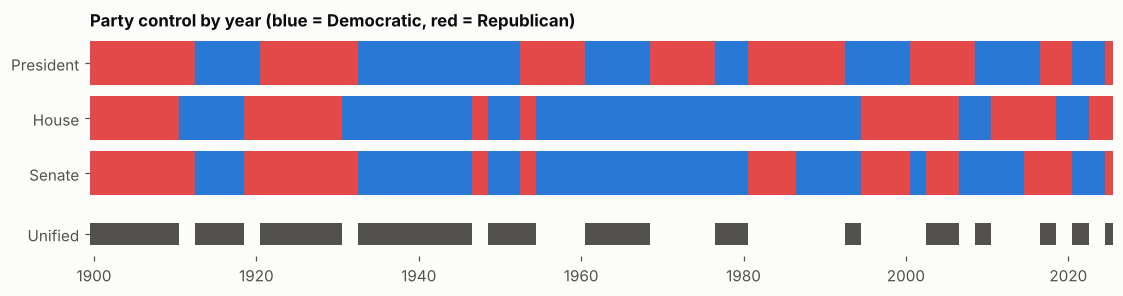

Share of years with a Democratic President 48%, House 60%, Senate 57%; unified government 57%


In [2]:
p = panel.loc[1900:2025]
fig, ax = plt.subplots(figsize=(12, 2.6))
rows = [("President", "pres_party"), ("House", "house_party"), ("Senate", "senate_party")]
for i, (name, col) in enumerate(rows):
    for yr, party in p[col].items():
        ax.add_patch(mpatches.Rectangle((yr - 0.5, 2 - i), 1, 0.8, color=D if party == "D" else R, lw=0))
for yr, u in p["unified"].items():
    if u:
        ax.add_patch(mpatches.Rectangle((yr - 0.5, -0.9), 1, 0.4, color=INK2, lw=0))
ax.set_yticks([2.4, 1.4, 0.4, -0.7], ["President", "House", "Senate", "Unified"])
ax.set_xlim(1899.5, 2025.5); ax.set_ylim(-1.1, 2.9); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Party control by year (blue = Democratic, red = Republican)")
plt.show()
print(f"Share of years with a Democratic President {p.dem_pres.mean():.0%}, House {p.dem_house.mean():.0%}, "
      f"Senate {p.dem_senate.mean():.0%}; unified government {p.unified.mean():.0%}")

## 2. Every outcome over time
These are the exact series tested (annual changes). Background shading = the president's party that year. If party mattered a lot, the line would sit visibly higher or lower in one colour.

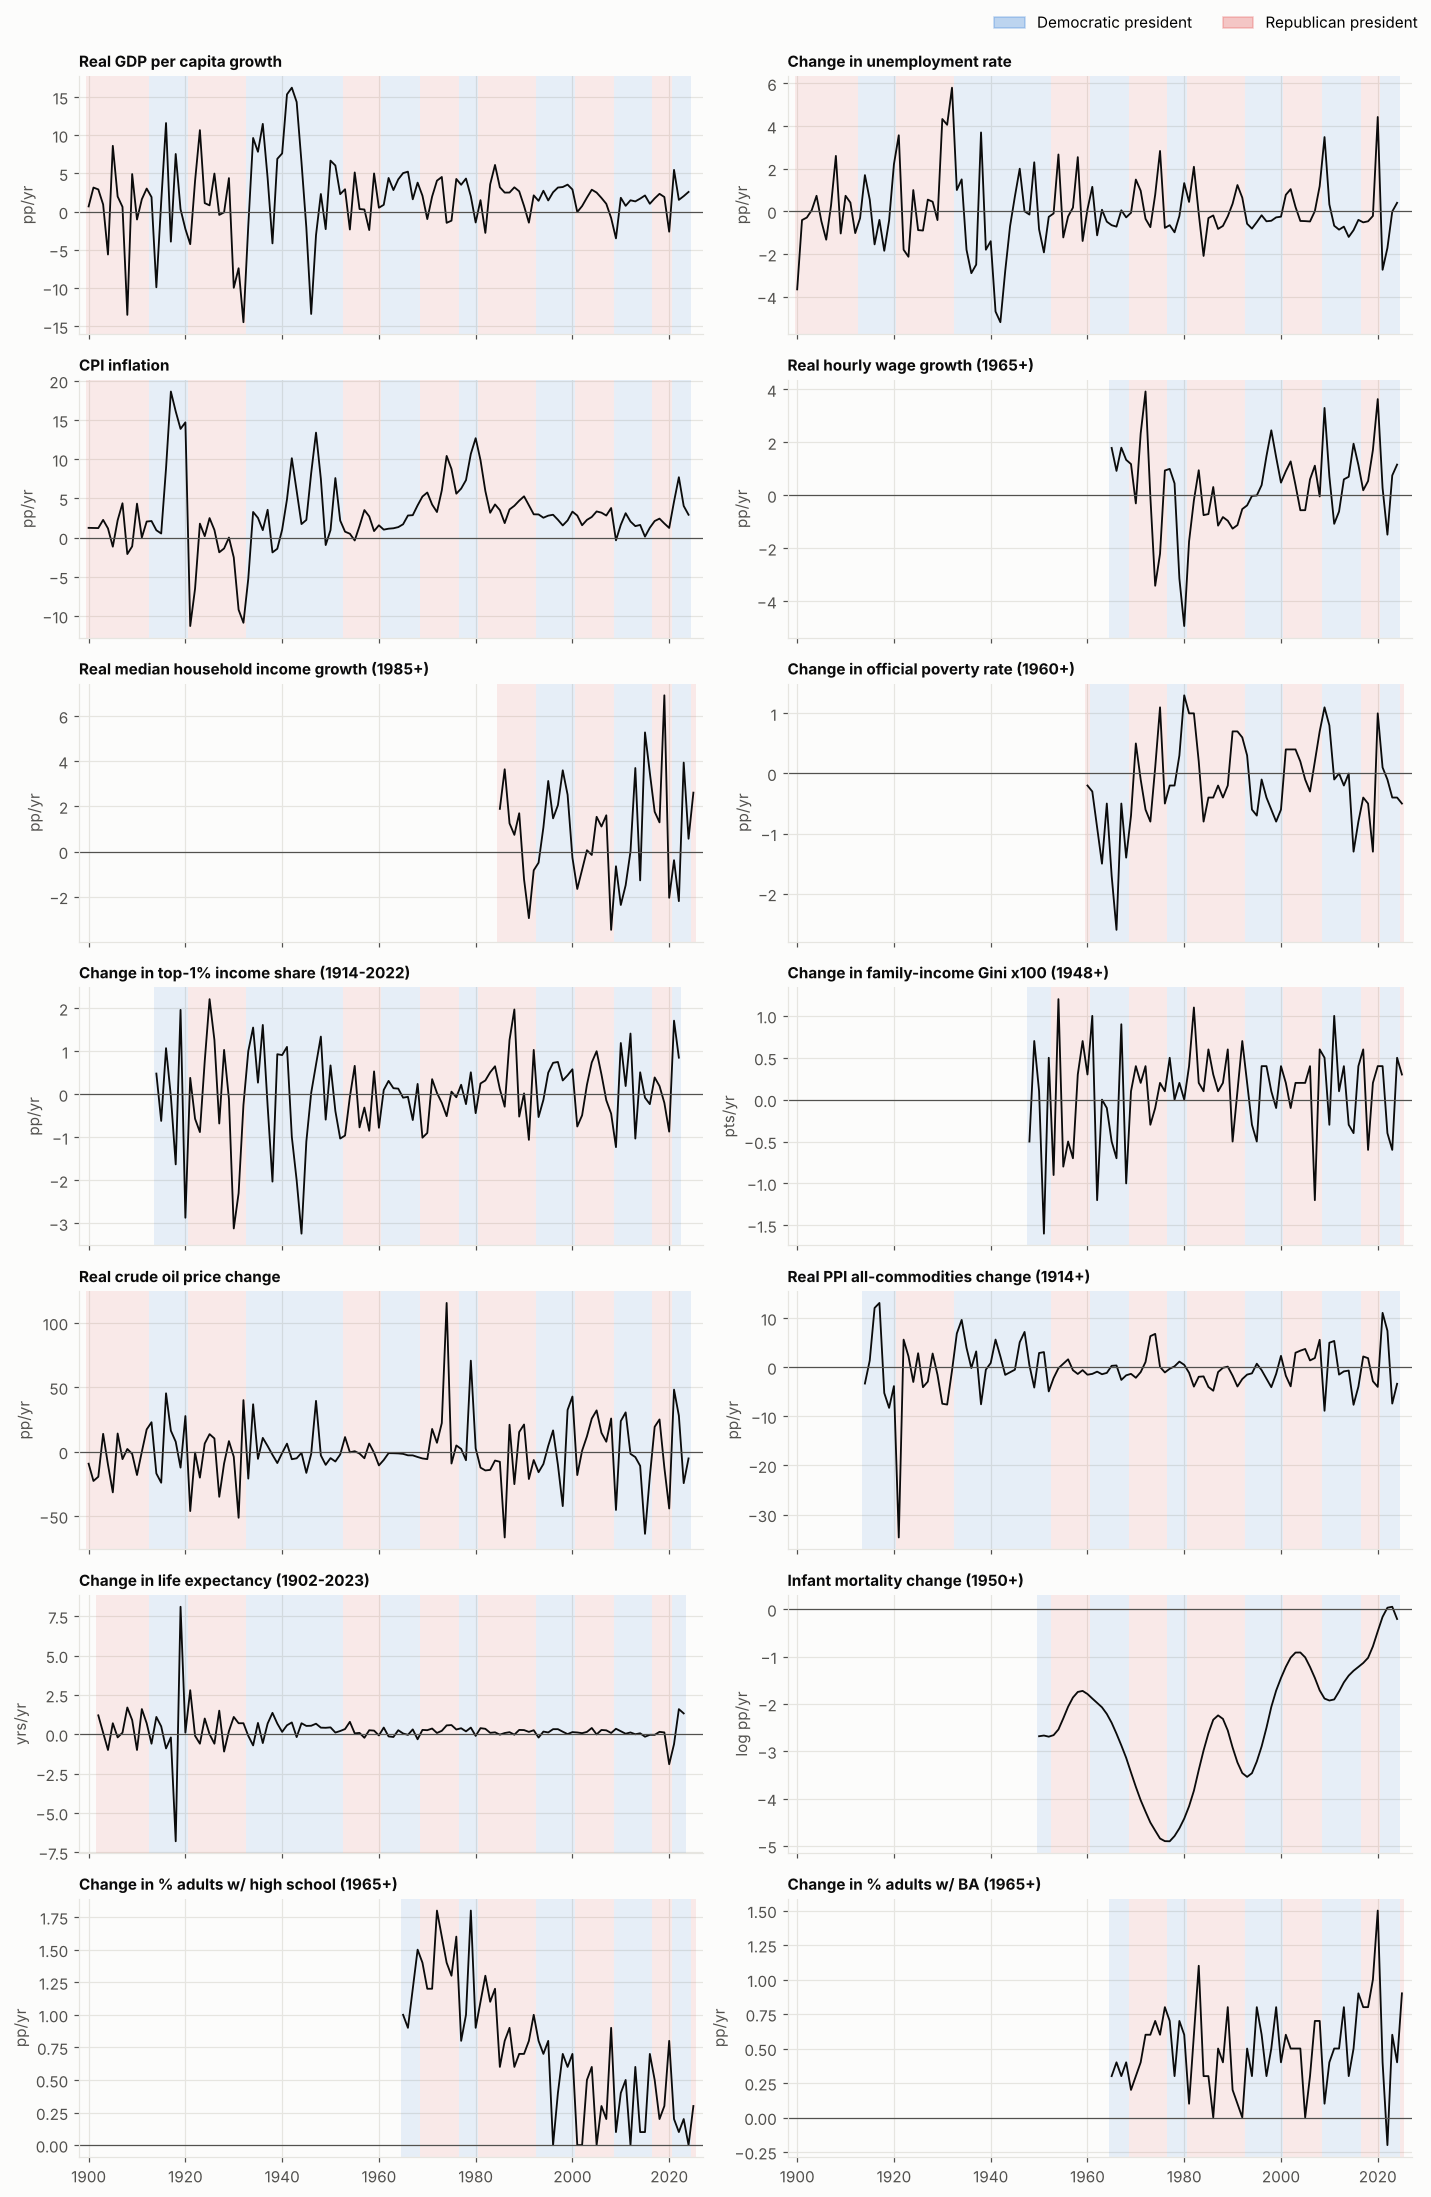

In [3]:
outs = list(OUTCOMES)
fig, axes = plt.subplots(7, 2, figsize=(13, 20), sharex=True)
for ax, y in zip(axes.flat, outs):
    s = panel[y].loc[1900:2025].dropna()
    shade_presidents(ax, s.index.min(), s.index.max())
    ax.plot(s.index, s.values, color=INK, lw=1.2)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(label[y], fontsize=10)
    ax.set_ylabel(units[y])
for ax in axes[-1]: ax.set_xlim(1898, 2027)
fig.legend(handles=[mpatches.Patch(color=D, alpha=.3, label="Democratic president"),
                    mpatches.Patch(color=R, alpha=.3, label="Republican president")],
           loc="upper right", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.985)); plt.show()

## 3. Term-level test (T4)
Each dot is one 4-year presidential term (years 2–5 after inauguration, so a president is judged on his own economy). Horizontal ticks are the party means. `p` is the 20,000-shuffle permutation p-value; `q` is after Benjamini–Hochberg correction across all 14 outcomes. Nothing reaches q < 0.05.

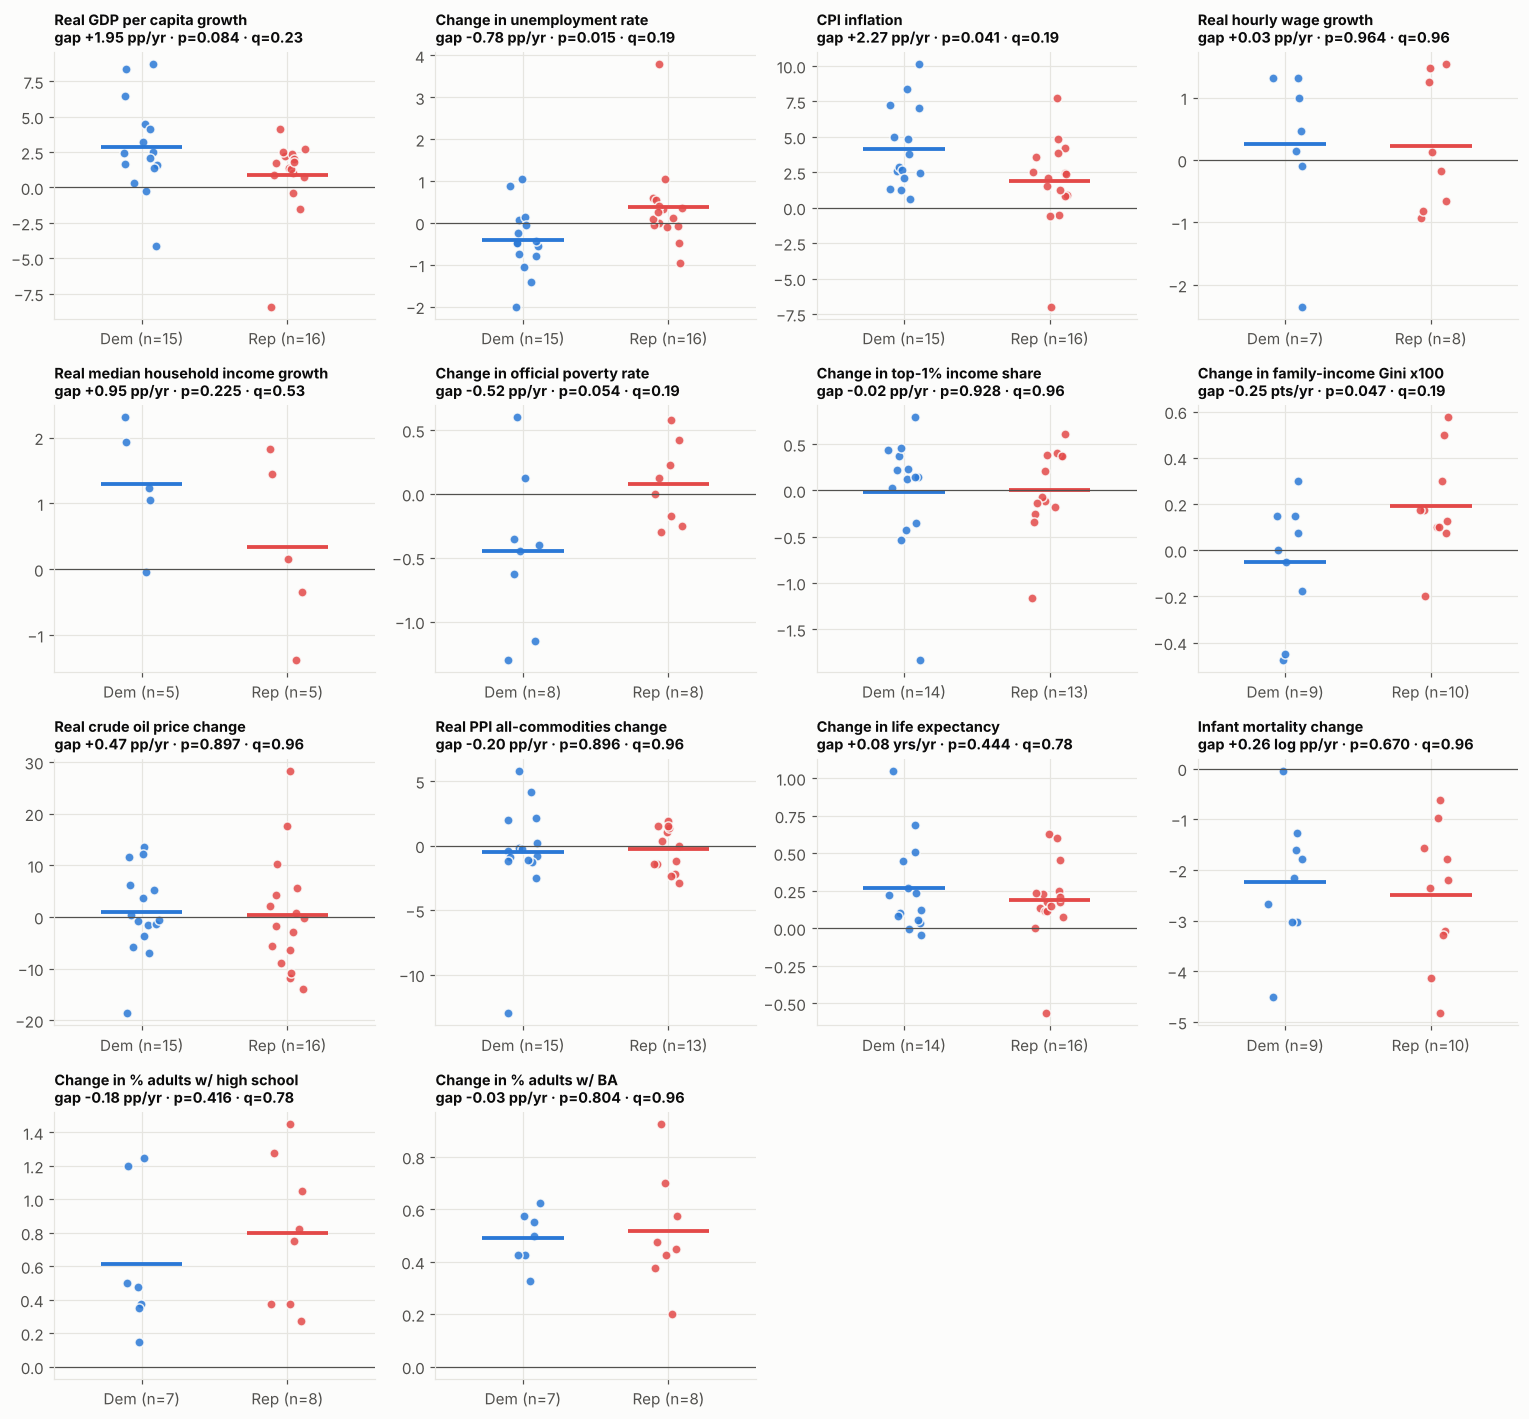

,outcome,n_D,n_R,mean_D,mean_R,diff_D_minus_R,p_welch,p_mannwhitney,p_perm,q_bh_perm,mde80
0,gdp_pc_growth,15,16,2.854,0.903,1.952,0.088,0.109,0.084,0.235,3.202
1,unemp_change,15,16,-0.409,0.368,-0.778,0.024,0.013,0.015,0.191,0.948
2,inflation,15,16,4.148,1.874,2.273,0.044,0.060,0.041,0.191,3.133
3,real_wage_growth,7,8,0.253,0.225,0.028,0.964,0.779,0.964,0.964,1.858
4,real_med_hh_inc_growth,5,5,1.293,0.340,0.953,0.223,0.310,0.225,0.526,2.321
5,poverty_change,8,8,-0.444,0.078,-0.522,0.059,0.046,0.054,0.191,0.762
6,top1_change,14,13,-0.015,0.005,-0.020,0.926,0.942,0.928,0.964,0.625
7,gini_change,9,10,-0.053,0.193,-0.245,0.047,0.072,0.047,0.191,0.340
8,real_oil_return,15,16,0.877,0.409,0.468,0.896,0.594,0.897,0.964,10.276
9,real_commodity_return,15,13,-0.491,-0.290,-0.201,0.865,0.678,0.896,0.964,3.438


In [4]:
fig, axes = plt.subplots(4, 4, figsize=(14, 13))
rng = np.random.default_rng(0)
for ax, (_, r) in zip(axes.flat, term_tests.iterrows()):
    t = term_vals[term_vals.outcome == r.outcome]
    for x, party, col in [(0, "D", D), (1, "R", R)]:
        v = t[t.party == party].value.values
        ax.scatter(x + rng.uniform(-.12, .12, len(v)), v, s=36, color=col, alpha=.85, edgecolor=SURF, lw=1)
        ax.hlines(v.mean(), x - .28, x + .28, color=col, lw=2.5)
    ax.axhline(0, color=INK2, lw=.8)
    ax.set_xticks([0, 1], [f"Dem (n={r.n_D})", f"Rep (n={r.n_R})"]); ax.set_xlim(-.6, 1.6)
    ax.set_title(f"{label[r.outcome].split(' (')[0]}\ngap {r.diff_D_minus_R:+.2f} {units[r.outcome]} · p={r.p_perm:.3f} · q={r.q_bh_perm:.2f}",
                 fontsize=9.5)
for ax in axes.flat[len(term_tests):]: ax.axis("off")
fig.tight_layout(); plt.show()
display(term_tests[["outcome", "n_D", "n_R", "mean_D", "mean_R", "diff_D_minus_R", "p_welch", "p_mannwhitney",
                    "p_perm", "q_bh_perm", "mde80"]].round(3))

## 4. Equivalence: which nulls are *proven*?
"Not significant" does not mean "no effect". Here each gap is divided by the smallest effect I pre-declared as meaningful, with its 90% confidence interval (the interval used by a TOST equivalence test). A whisker entirely inside the grey band means the effect is provably negligible; only oil and commodity prices get there.

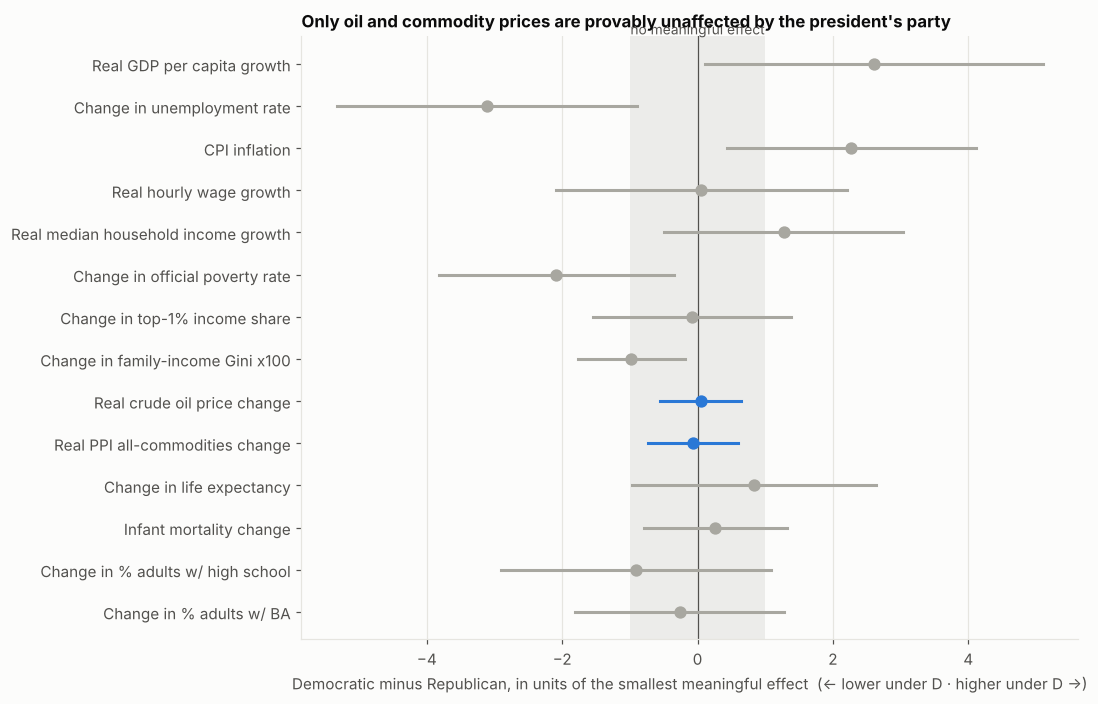

,outcome,sesoi,diff_D_minus_R,p_tost,verdict
0,gdp_pc_growth,0.75,1.952,0.857,inconclusive
1,unemp_change,0.25,-0.778,0.941,inconclusive
2,inflation,1.00,2.273,0.876,inconclusive
3,real_wage_growth,0.50,0.028,0.226,inconclusive
4,real_med_hh_inc_growth,0.75,0.953,0.608,inconclusive
5,poverty_change,0.25,-0.522,0.853,inconclusive
6,top1_change,0.25,-0.020,0.147,inconclusive
7,gini_change,0.25,-0.245,0.484,inconclusive
8,real_oil_return,10.00,0.468,0.006,equivalent (null accepted)
9,real_commodity_return,3.00,-0.201,0.013,equivalent (null accepted)


In [5]:
from scipy import stats
t = term_tests.copy()
dfree = t.n_D + t.n_R - 2
crit = stats.t.ppf(0.95, dfree)
t["gap"] = t.diff_D_minus_R / t.sesoi
t["lo"] = (t.diff_D_minus_R - crit * t.se) / t.sesoi
t["hi"] = (t.diff_D_minus_R + crit * t.se) / t.sesoi
t["inside"] = (t.lo >= -1) & (t.hi <= 1)
t = t.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.axvspan(-1, 1, color=GREY, alpha=.18, lw=0)
ax.axvline(0, color=INK2, lw=.8)
for i, (_, r) in enumerate(t.iterrows()):
    c = D if r.inside else GREY
    ax.plot([r.lo, r.hi], [i, i], color=c, lw=2)
    ax.scatter(r.gap, i, s=50, color=c, zorder=3)
ax.set_yticks(range(len(t)), [label[o].split(" (")[0] for o in t.outcome])
ax.set_xlabel("Democratic minus Republican, in units of the smallest meaningful effect  (← lower under D · higher under D →)")
ax.text(0, len(t) - .3, "no meaningful effect", ha="center", color=INK2, fontsize=9)
ax.set_title("Only oil and commodity prices are provably unaffected by the president's party")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
display(term_tests[["outcome", "sesoi", "diff_D_minus_R", "p_tost"]].assign(
    verdict=np.where(term_tests.p_tost < .05, "equivalent (null accepted)", "inconclusive")).round(3))

## 5. All 210 primary tests at a glance
Left: naive p-values from the annual regressions (Newey–West errors). Right: the same coefficients judged by the **rotation test**, which slides the party history against the outcome to build a null that keeps long party runs intact. Darker = smaller p. Cells marked ● survive FDR (q < 0.05). The left panel's dots all disappear on the right.

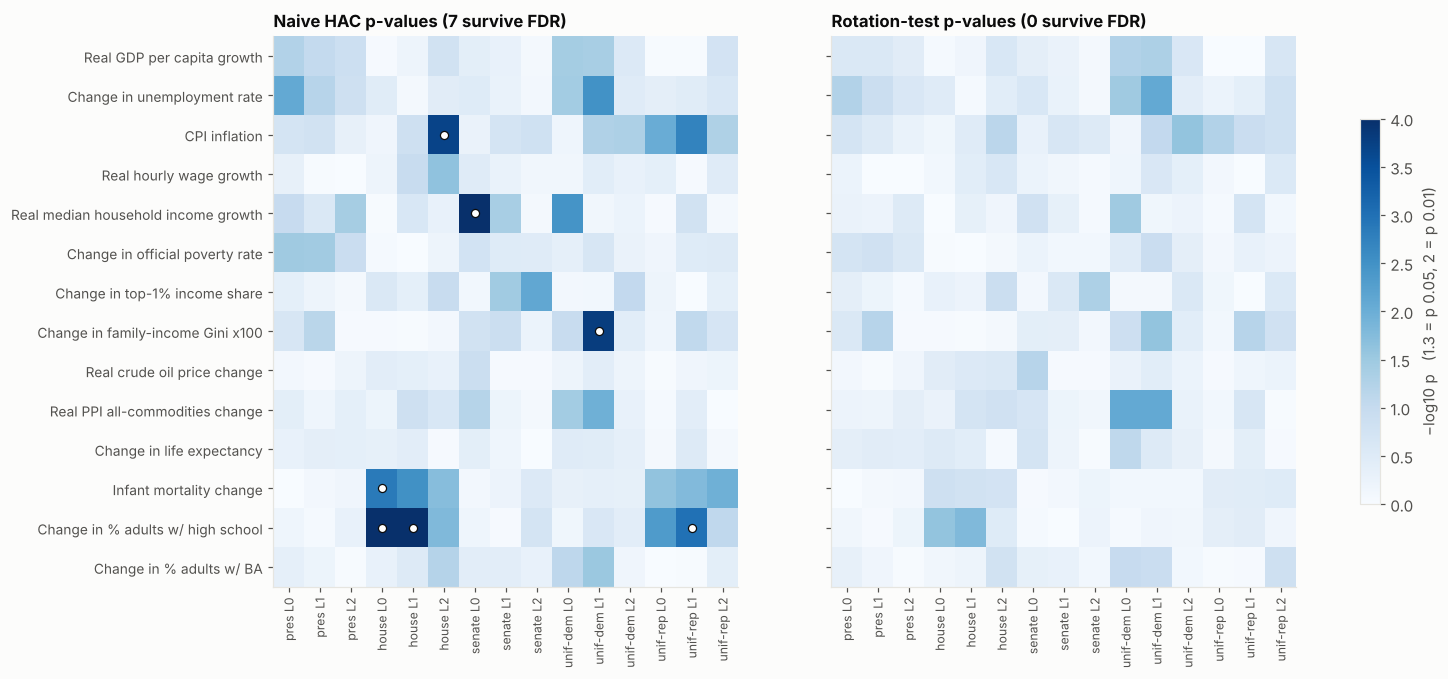

In [6]:
prim = annual[annual.model.isin(["T1 base", "T3 unified"])].copy()
prim["col"] = prim.term.str.replace("dem_", "").str.replace("unified_", "unif-") + " L" + prim.lag.astype(str)
r2 = rot.copy(); r2["col"] = r2.term.str.replace("dem_", "").str.replace("unified_", "unif-") + " L" + r2.lag.astype(str)
order = [f"{t} L{k}" for t in ["pres", "house", "senate", "unif-dem", "unif-rep"] for k in (0, 1, 2)]
rows = list(OUTCOMES)
def grid(df, pcol, qcol):
    P = df.pivot_table(index="outcome", columns="col", values=pcol).reindex(index=rows, columns=order)
    Q = df.pivot_table(index="outcome", columns="col", values=qcol).reindex(index=rows, columns=order)
    return P, Q
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)
for ax, (P, Q), title in [(axes[0], grid(prim, "p", "q_bh_primary"), "Naive HAC p-values (7 survive FDR)"),
                          (axes[1], grid(r2, "p_rotation", "q_rotation"), "Rotation-test p-values (0 survive FDR)")]:
    im = ax.imshow(-np.log10(P.values), cmap="Blues", vmin=0, vmax=4, aspect="auto")
    yy, xx = np.where(Q.values < .05)
    ax.scatter(xx, yy, s=28, color="white", edgecolor=INK, lw=.8)
    ax.set_xticks(range(len(order)), order, rotation=90, fontsize=8); ax.set_title(title); ax.grid(False)
axes[0].set_yticks(range(len(rows)), [label[r].split(" (")[0] for r in rows], fontsize=9)
cb = fig.colorbar(im, ax=axes, shrink=.7); cb.set_label("−log10 p   (1.3 = p 0.05, 2 = p 0.01)")
plt.show()

## 6. Why the Congress "effects" are artifacts
The strongest naive result was *a Democratic House raises high-school attainment growth by 0.62 pp/yr*. But Democrats held the House continuously 1955–1994, exactly when attainment was rising fastest because older, less-schooled cohorts were dying out. The party dummy is just an era marker. Add a time trend and the sign flips.

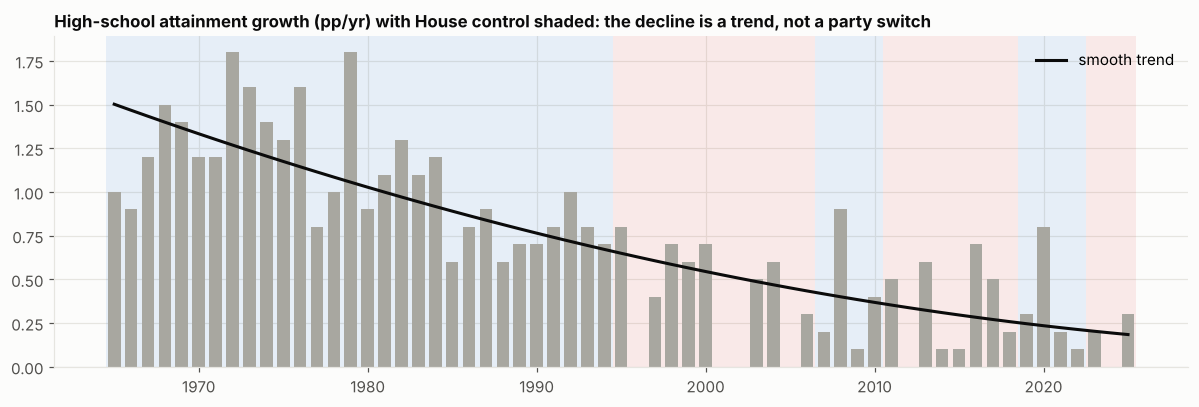

,lag,coef,coef_trend,p_trend,p_rotation
181,0,0.616,0.154,0.070,0.025
186,1,0.637,0.184,0.010,0.016
191,2,0.373,-0.239,0.003,0.320


In [7]:
s = panel.loc[1965:2025, "hs_attain_change"]
fig, ax = plt.subplots(figsize=(11, 3.8))
for yr, dh in panel.loc[1965:2025, "dem_house"].items():
    ax.axvspan(yr - .5, yr + .5, color=D if dh else R, alpha=.10, lw=0)
ax.bar(s.index, s.values, color=GREY, width=.75)
z = np.polyfit(s.index, s.values, 2); ax.plot(s.index, np.polyval(z, s.index), color=INK, lw=2, label="smooth trend")
ax.set_title("High-school attainment growth (pp/yr) with House control shaded: the decline is a trend, not a party switch")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
display(rot[(rot.outcome == "hs_attain_change") & (rot.term == "dem_house")][["lag", "coef", "coef_trend", "p_trend", "p_rotation"]].round(3))

## 7. The alternative hypothesis: inherited conditions
Each dot is a term. x = unemployment in the inauguration year (what the president inherited); y = average yearly change in unemployment over the term. High starting unemployment tends to fall on its own, and Democrats inherited worse labour markets (7.6% vs 5.2% on average). Lines are the fitted model with a common slope; the vertical gap between them is the party effect *after* adjusting for inheritance.

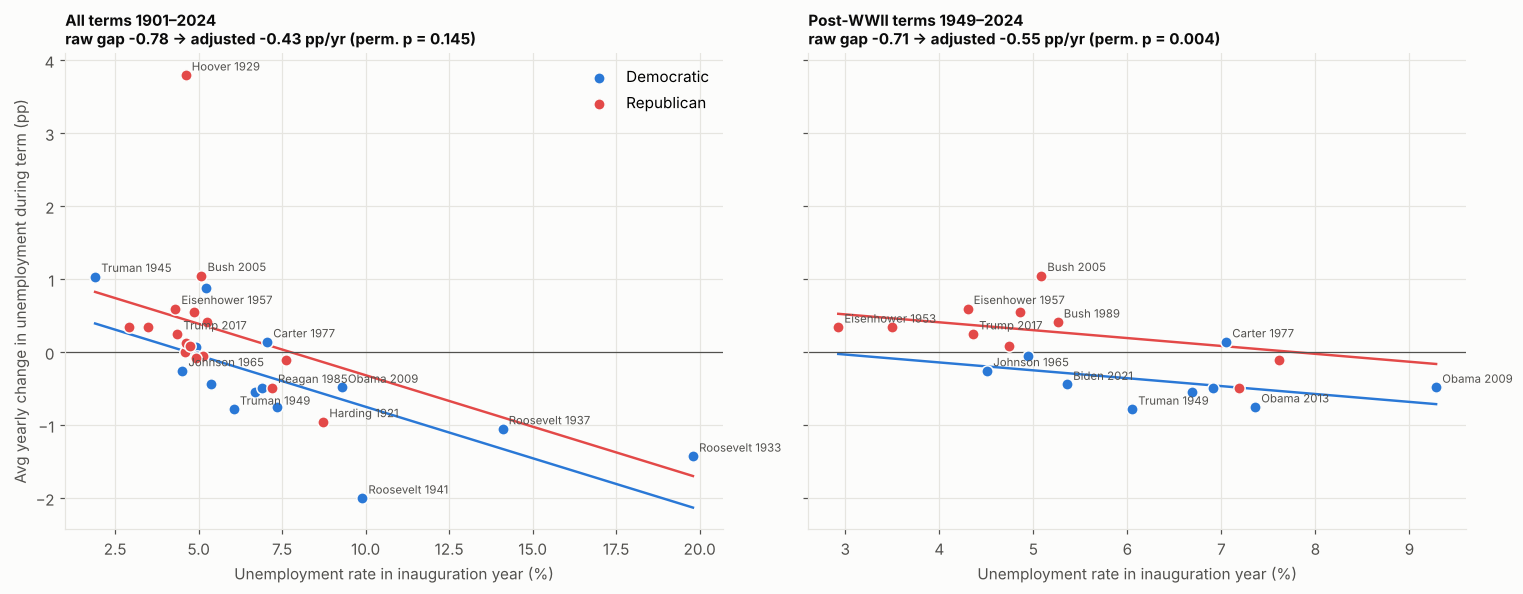

**Inherited-conditions adjustment, all outcomes tested**

,outcome,sample,n_terms,inherited_unemp_D,inherited_unemp_R,raw_gap,gap_adj_inherited,p_perm_adj,q_bh
0,gdp_pc_growth,all terms 1901+,31,7.601,5.152,1.952,0.533,0.589,0.642
1,gdp_pc_growth,post-WWII terms 1949+,19,6.461,4.982,1.104,1.130,0.038,0.065
2,unemp_change,all terms 1901+,31,7.601,5.152,-0.778,-0.433,0.145,0.218
3,unemp_change,post-WWII terms 1949+,19,6.461,4.982,-0.710,-0.550,0.004,0.014
4,inflation,all terms 1901+,31,7.601,5.152,2.273,2.836,0.011,0.034
5,inflation,post-WWII terms 1949+,19,6.461,4.982,0.064,-0.061,0.954,0.954
6,poverty_change,all terms 1901+,16,6.512,5.325,-0.522,-0.644,0.024,0.051
7,poverty_change,post-WWII terms 1949+,16,6.512,5.325,-0.522,-0.644,0.026,0.051
8,gini_change,all terms 1901+,19,6.461,4.982,-0.245,-0.365,0.001,0.006
9,gini_change,post-WWII terms 1949+,19,6.461,4.982,-0.245,-0.365,0.001,0.006


**Post-WWII stress test: + linear trend, and leave-one-term-out range**

,outcome,gap_adj_inherited_and_trend,p_perm,loo_min,loo_max
0,unemp_change,-0.545,0.008,-0.687,-0.463
1,gdp_pc_growth,1.076,0.040,0.858,1.449
2,gini_change,-0.358,0.002,-0.433,-0.308
3,poverty_change,-0.646,0.032,-0.793,-0.466


In [8]:
t = term_vals[term_vals.outcome == "unemp_change"].copy()
t["u0"] = panel.loc[t.term_start, "unemp"].values
t["Dm"] = (t.party == "D").astype(int)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, (name, mask) in zip(axes, [("All terms 1901–2024", t.term_start >= 1901), ("Post-WWII terms 1949–2024", t.term_start >= 1949)]):
    s = t[mask]
    X = np.column_stack([np.ones(len(s)), s.Dm, s.u0]); b = np.linalg.lstsq(X, s.value, rcond=None)[0]
    xs = np.linspace(s.u0.min(), s.u0.max(), 50)
    for dm, col, lab in [(1, D, "Democratic"), (0, R, "Republican")]:
        ss = s[s.Dm == dm]
        ax.scatter(ss.u0, ss.value, s=55, color=col, edgecolor=SURF, lw=1, label=lab, zorder=3)
        ax.plot(xs, b[0] + b[1] * dm + b[2] * xs, color=col, lw=1.6)
    a = alt[(alt.outcome == "unemp_change") & (alt["sample"].str.startswith("all" if "All" in name else "post"))].iloc[0]
    ax.set_title(f"{name}\nraw gap {a.raw_gap:+.2f} → adjusted {a.gap_adj_inherited:+.2f} pp/yr (perm. p = {a.p_perm_adj:.3f})", fontsize=10)
    ax.axhline(0, color=INK2, lw=.8); ax.set_xlabel("Unemployment rate in inauguration year (%)")
    label_points(ax, s.u0, s.value, [f"{p.split()[-1]} {int(y)}" for p, y in zip(s.president, s.term_start)])
axes[0].set_ylabel("Avg yearly change in unemployment during term (pp)"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
display(Markdown("**Inherited-conditions adjustment, all outcomes tested**")); display(alt.round(3))
display(Markdown("**Post-WWII stress test: + linear trend, and leave-one-term-out range**")); display(stress.round(3))

## 8. Machine-learning check (scikit-learn)
A ridge model forecasts each outcome one year ahead using only its own past, war/depression flags and a trend, retrained every year (expanding window). Then party features are added. Bars show the % reduction in out-of-sample forecast error from adding party; grey ticks are what shuffled (fake) party labels achieve on average. Party information beats fake labels nowhere after correction.

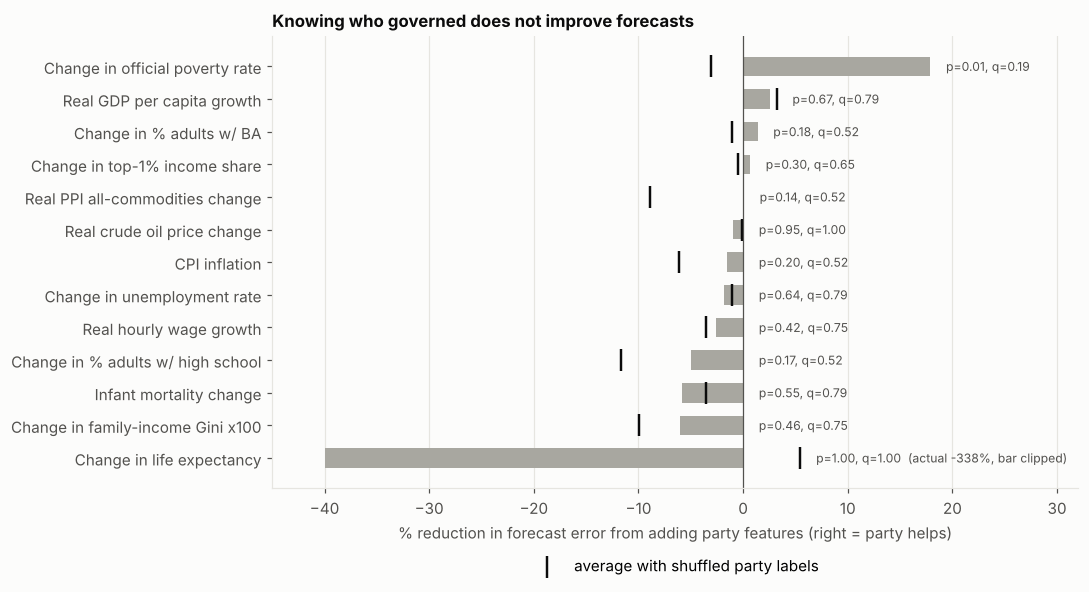

,outcome,n_oos,mse_base,mse_with_party,oos_gain_pct,null_mean_gain_pct,p_perm,q_bh
0,gdp_pc_growth,95,23.789,23.167,2.616,3.213,0.672,0.794
1,unemp_change,95,3.146,3.204,-1.839,-1.041,0.637,0.794
2,inflation,95,7.686,7.805,-1.537,-6.139,0.199,0.517
3,real_wage_growth,28,1.551,1.591,-2.580,-3.506,0.418,0.752
4,poverty_change,34,0.343,0.282,17.890,-3.043,0.015,0.194
5,top1_change,77,0.492,0.488,0.661,-0.490,0.299,0.647
6,gini_change,43,0.202,0.214,-6.062,-9.940,0.463,0.752
7,real_oil_return,95,634.395,640.737,-1.000,-0.086,0.950,1.000
8,real_commodity_return,79,12.239,12.229,0.080,-8.941,0.144,0.517
9,life_exp_change,90,0.202,0.885,-338.023,5.478,1.000,1.000


In [9]:
m = ml.sort_values("oos_gain_pct")
clip = m.oos_gain_pct.clip(lower=-40)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(range(len(m)), clip, color=[D if (g > 0 and q < .05) else GREY for g, q in zip(m.oos_gain_pct, m.q_bh)], height=.6)
ax.scatter(m.null_mean_gain_pct.clip(lower=-40), range(len(m)), marker="|", s=200, color=INK, label="average with shuffled party labels")
for i, (_, r) in enumerate(m.iterrows()):
    note = f"p={r.p_perm:.2f}, q={r.q_bh:.2f}" + (f"  (actual {r.oos_gain_pct:.0f}%, bar clipped)" if r.oos_gain_pct < -40 else "")
    ax.text(max(clip.iloc[i], 0, r.null_mean_gain_pct) + 1.5, i, note, va="center", fontsize=8, color=INK2)
ax.set_yticks(range(len(m)), [label[o].split(" (")[0] for o in m.outcome]); ax.axvline(0, color=INK2, lw=.8)
ax.set_xlabel("% reduction in forecast error from adding party features (right = party helps)")
ax.set_xlim(-45, 32)
ax.set_title("Knowing who governed does not improve forecasts")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
display(ml.round(3))

## 9. Reverse causality
The economy in an election year vs whether the incumbent party held the White House. Bad years tend to hand power to the challenger, which is why the next president often inherits a recovery.

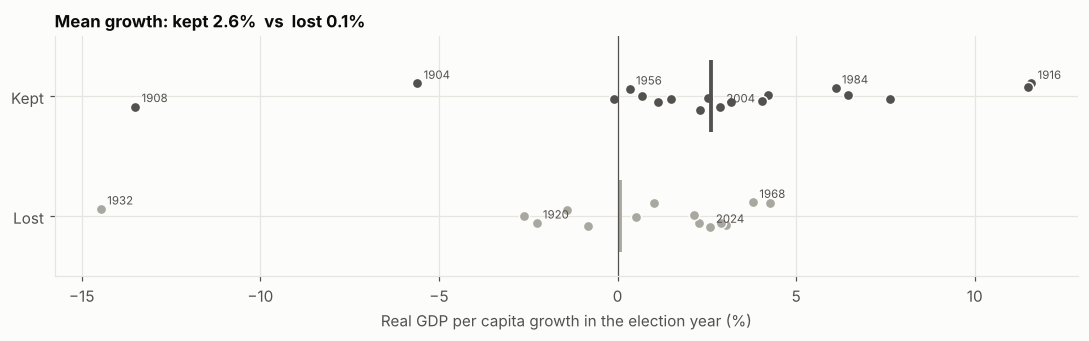

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.2))
rng = np.random.default_rng(1)
for kept, col, name in [(1, INK2, "Incumbent party kept the White House"), (0, GREY, "Incumbent party lost")]:
    s = elec[elec.incumbent_kept == kept]
    yv = kept + rng.uniform(-.12, .12, len(s))
    ax.scatter(s.gdp_growth, yv, s=45, color=col, edgecolor=SURF, label=name)
    ax.vlines(s.gdp_growth.mean(), kept - .3, kept + .3, color=col, lw=2.5)
    ax.set_ylim(-.5, 1.5)
    label_points(ax, s.gdp_growth.values, yv, [str(int(e)) for e in s.election], frac=0.06)
ax.set_yticks([0, 1], ["Lost", "Kept"]); ax.axvline(0, color=INK2, lw=.8)
ax.set_xlabel("Real GDP per capita growth in the election year (%)")
ax.set_title(f"Mean growth: kept {elec[elec.incumbent_kept==1].gdp_growth.mean():.1f}%  vs  lost {elec[elec.incumbent_kept==0].gdp_growth.mean():.1f}%")
plt.tight_layout(); plt.show()

## 10. Full output tables
Every results file, unabridged. Scroll inside each table.

In [11]:
for f in sorted(RES.glob("*.csv")):
    display(Markdown(f"### `results/{f.name}`"))
    display(pd.read_csv(f).round(4))

### `results/alternative_inherited_conditions.csv`

,outcome,sample,n_terms,inherited_unemp_D,inherited_unemp_R,raw_gap,gap_adj_inherited,p_perm_adj,q_bh
0,gdp_pc_growth,all terms 1901+,31,7.6007,5.1516,1.9516,0.5331,0.5886,0.6421
1,gdp_pc_growth,post-WWII terms 1949+,19,6.4611,4.9825,1.1044,1.1305,0.0380,0.0651
2,unemp_change,all terms 1901+,31,7.6007,5.1516,-0.7777,-0.4325,0.1452,0.2178
3,unemp_change,post-WWII terms 1949+,19,6.4611,4.9825,-0.7100,-0.5501,0.0036,0.0144
4,inflation,all terms 1901+,31,7.6007,5.1516,2.2734,2.8360,0.0115,0.0345
5,inflation,post-WWII terms 1949+,19,6.4611,4.9825,0.0637,-0.0606,0.9542,0.9542
6,poverty_change,all terms 1901+,16,6.5125,5.3250,-0.5219,-0.6444,0.0237,0.0512
7,poverty_change,post-WWII terms 1949+,16,6.5125,5.3250,-0.5219,-0.6444,0.0256,0.0512
8,gini_change,all terms 1901+,19,6.4611,4.9825,-0.2453,-0.3647,0.0007,0.0057
9,gini_change,post-WWII terms 1949+,19,6.4611,4.9825,-0.2453,-0.3647,0.0009,0.0057


### `results/alternative_post_wwii_stress.csv`

,outcome,gap_adj_inherited_and_trend,p_perm,loo_min,loo_max
0,unemp_change,-0.5454,0.0076,-0.6865,-0.4625
1,gdp_pc_growth,1.0762,0.0404,0.8580,1.4486
2,gini_change,-0.3585,0.0021,-0.4331,-0.3084
3,poverty_change,-0.6463,0.0319,-0.7931,-0.4665


### `results/annual_models.csv`

,outcome,lag,model,term,coef,se,p,n,years,q_bh_primary,q_bh_all
0,gdp_pc_growth,0,T1 base,dem_pres,1.5113,0.7973,0.0580,125,1900-2024,0.3383,0.3480
1,gdp_pc_growth,0,T1 base,dem_house,0.1310,1.1944,0.9127,125,1900-2024,0.9857,0.9840
2,gdp_pc_growth,0,T1 base,dem_senate,1.0745,1.2799,0.4012,125,1900-2024,0.7990,0.7900
3,gdp_pc_growth,0,T2 controls,dem_pres,1.3363,0.7384,0.0703,124,1901-2024,NaN,0.3693
4,gdp_pc_growth,0,T2 controls,dem_house,0.1507,0.7814,0.8471,124,1901-2024,NaN,0.9687
5,gdp_pc_growth,0,T2 controls,dem_senate,0.4256,0.9239,0.6451,124,1901-2024,NaN,0.8780
6,gdp_pc_growth,0,T3 unified,unified_dem,2.4333,1.1721,0.0379,125,1900-2024,0.2743,0.2767
7,gdp_pc_growth,0,T3 unified,unified_rep,-0.0537,0.7503,0.9429,125,1900-2024,0.9857,0.9851
8,gdp_pc_growth,1,T1 base,dem_pres,1.5225,0.9071,0.0933,125,1900-2024,0.4353,0.4353
9,gdp_pc_growth,1,T1 base,dem_house,0.4550,0.9722,0.6398,125,1900-2024,0.8882,0.8780


... (10 outputs left out)

### `results/term_level_tests.csv`

,outcome,n_D,n_R,mean_D,mean_R,diff_D_minus_R,se,cohens_d,p_welch,p_mannwhitney,p_perm,sesoi,p_tost,mde80,first_term,last_term,q_bh_perm
0,gdp_pc_growth,15,16,2.8545,0.9029,1.9516,1.1025,0.6397,0.0878,0.1094,0.0839,0.75,0.8574,3.2024,1901,2021,0.2349
1,unemp_change,15,16,-0.4094,0.3683,-0.7777,0.3266,-0.8486,0.0243,0.0135,0.0145,0.25,0.9413,0.9481,1901,2021,0.1907
2,inflation,15,16,4.1477,1.8743,2.2734,1.0807,0.7537,0.0442,0.0604,0.0408,1.00,0.8759,3.1334,1901,2021,0.1907
3,real_wage_growth,7,8,0.2534,0.2254,0.0279,0.6075,0.0241,0.9641,0.7789,0.9641,0.50,0.2263,1.8580,1965,2021,0.9641
4,real_med_hh_inc_growth,5,5,1.2930,0.3401,0.9530,0.7134,0.8449,0.2228,0.3095,0.2254,0.75,0.6079,2.3207,1985,2021,0.5259
5,poverty_change,8,8,-0.4438,0.0781,-0.5219,0.2464,-1.0590,0.0590,0.0458,0.0545,0.25,0.8527,0.7619,1961,2021,0.1907
6,top1_change,14,13,-0.0148,0.0054,-0.0202,0.2138,-0.0360,0.9255,0.9420,0.9282,0.25,0.1466,0.6248,1913,2017,0.9641
7,gini_change,9,10,-0.0528,0.1925,-0.2453,0.1137,-1.0017,0.0470,0.0722,0.0466,0.25,0.4837,0.3399,1949,2021,0.1907
8,real_oil_return,15,16,0.8766,0.4086,0.4680,3.5383,0.0471,0.8957,0.5936,0.8965,10.00,0.0059,10.2763,1901,2021,0.9641
9,real_commodity_return,15,13,-0.4906,-0.2900,-0.2006,1.1647,-0.0619,0.8650,0.6784,0.8960,3.00,0.0132,3.4380,1913,2021,0.9641


### `results/term_level_values.csv`

,term_start,party,president,value,outcome
0,1901,R,McKinley,1.7142,gdp_pc_growth
1,1905,R,T. Roosevelt,-1.4932,gdp_pc_growth
2,1909,R,Taft,1.3828,gdp_pc_growth
3,1913,D,Wilson,-0.2414,gdp_pc_growth
4,1917,D,Wilson,0.3351,gdp_pc_growth
5,1921,R,Harding,4.1568,gdp_pc_growth
6,1925,R,Coolidge,2.2156,gdp_pc_growth
7,1929,R,Hoover,-8.4117,gdp_pc_growth
8,1933,D,F. Roosevelt,8.3358,gdp_pc_growth
9,1937,D,F. Roosevelt,6.4300,gdp_pc_growth


In [12]:
display(Markdown("### `data/panel.csv` (the analysis dataset, one row per year)"))
display(panel.round(3))

### `data/panel.csv` (the analysis dataset, one row per year)

,president,pres_party,congress,house_party,senate_party,dem_pres,dem_house,dem_senate,unified,unified_dem,unified_rep,term_start,cpi,gdp_pc,unemp,fed_outlays_gdp,war,ppi_all,wage_nom,med_hh_inc,oil_nom,gini,top1,poverty,life_exp,inf_mort,hs_attain,ba_attain,gdp_pc_growth,unemp_change,inflation,real_wage_growth,real_med_hh_inc_growth,poverty_change,top1_change,gini_change,real_oil_return,real_commodity_return,life_exp_change,inf_mort_change,hs_attain_change,ba_attain_change
year,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1898,McKinley,R,55,?,?,0,0,0,0,0,0,1897,8.04,6489.23,11.620,2.378,1.0,NaN,NaN,NaN,5.724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.591,-0.810,0.000,NaN,NaN,NaN,NaN,NaN,14.141,NaN,NaN,NaN,NaN,NaN
1899,McKinley,R,56,R,R,0,0,0,1,0,1,1897,8.04,6810.01,8.660,3.007,1.0,NaN,NaN,NaN,8.114,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.825,-2.960,0.000,NaN,NaN,NaN,NaN,NaN,34.895,NaN,NaN,NaN,NaN,NaN
1900,McKinley,R,56,R,R,0,0,0,1,0,1,1897,8.14,6857.02,5.000,2.459,1.0,NaN,NaN,NaN,7.485,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.688,-3.660,1.236,NaN,NaN,NaN,NaN,NaN,-9.305,NaN,NaN,NaN,NaN,NaN
1901,McKinley,R,57,R,R,0,0,0,1,0,1,1901,8.24,7076.79,4.590,2.286,1.0,NaN,NaN,NaN,6.038,NaN,NaN,NaN,49.300,NaN,NaN,NaN,3.155,-0.410,1.221,NaN,NaN,NaN,NaN,NaN,-22.699,NaN,NaN,NaN,NaN,NaN
1902,T. Roosevelt,R,57,R,R,0,0,0,1,0,1,1901,8.34,7285.57,4.300,1.961,1.0,NaN,NaN,NaN,5.032,NaN,NaN,NaN,50.500,NaN,NaN,NaN,2.908,-0.290,1.206,NaN,NaN,NaN,NaN,NaN,-19.438,NaN,1.200,NaN,NaN,NaN
1903,T. Roosevelt,R,58,R,R,0,0,0,1,0,1,1901,8.53,7354.36,4.350,1.942,0.0,NaN,NaN,NaN,5.912,NaN,NaN,NaN,50.600,NaN,NaN,NaN,0.940,0.050,2.253,NaN,NaN,NaN,NaN,NaN,13.874,NaN,0.100,NaN,NaN,NaN
1904,T. Roosevelt,R,58,R,R,0,0,0,1,0,1,1901,8.63,6953.86,5.080,2.216,0.0,NaN,NaN,NaN,5.409,NaN,NaN,NaN,49.600,NaN,NaN,NaN,-5.600,0.730,1.166,NaN,NaN,NaN,NaN,NaN,-10.060,NaN,-1.000,NaN,NaN,NaN
1905,T. Roosevelt,R,59,R,R,0,0,0,1,0,1,1905,8.53,7579.04,4.620,1.920,0.0,NaN,NaN,NaN,3.900,NaN,NaN,NaN,50.300,NaN,NaN,NaN,8.609,-0.460,-1.166,NaN,NaN,NaN,NaN,NaN,-31.556,NaN,0.700,NaN,NaN,NaN
1906,T. Roosevelt,R,59,R,R,0,0,0,1,0,1,1905,8.72,7730.64,3.290,1.795,0.0,NaN,NaN,NaN,4.592,NaN,NaN,NaN,50.100,NaN,NaN,NaN,1.981,-1.330,2.203,NaN,NaN,NaN,NaN,NaN,14.130,NaN,-0.200,NaN,NaN,NaN


## 11. Plot any outcome yourself
Change the name in the last line to any column of `panel` (levels like `unemp`, `poverty`, `life_exp`, `gdp_pc`, `oil_nom` work too).

Columns you can plot: congress, dem_pres, dem_house, dem_senate, unified, unified_dem, unified_rep, term_start, cpi, gdp_pc, unemp, fed_outlays_gdp, war, ppi_all, wage_nom, med_hh_inc, oil_nom, gini, top1, poverty, life_exp, inf_mort, hs_attain, ba_attain, gdp_pc_growth, unemp_change, inflation, real_wage_growth, real_med_hh_inc_growth, poverty_change, top1_change, gini_change, real_oil_return, real_commodity_return, life_exp_change, inf_mort_change, hs_attain_change, ba_attain_change


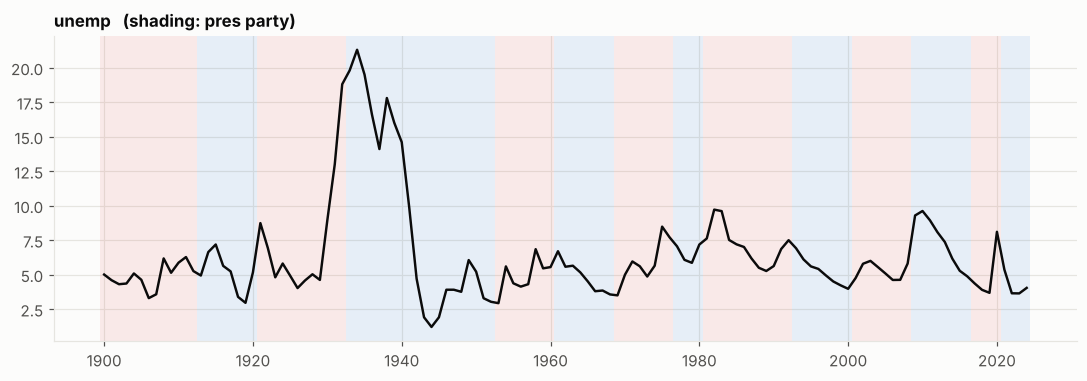

In [13]:
def plot_outcome(col, y0=1900, y1=2025, shade="pres"):
    s = panel[col].loc[y0:y1].dropna()
    fig, ax = plt.subplots(figsize=(12, 3.6))
    key = {"pres": "dem_pres", "house": "dem_house", "senate": "dem_senate"}[shade]
    for yr, dem in panel.loc[s.index.min():s.index.max(), key].items():
        ax.axvspan(yr - .5, yr + .5, color=D if dem else R, alpha=.10, lw=0)
    ax.plot(s.index, s.values, color=INK)
    ax.set_title(f"{label.get(col, col)}   (shading: {shade} party)"); plt.show()

print("Columns you can plot:", ", ".join(panel.select_dtypes("number").columns))
plot_outcome("unemp", shade="pres")